# Orthogonal learning, by hand: why the doubly robust score works

**Question:** we want the ATE of surgery from observational data with several covariates and nonlinear confounding,
so we fit ML models for the outcome $\mu_t(x) = E[Y|T=t, X=x]$ and the propensity $e(x) = P(T=1|X=x)$. These
*nuisance* models are always somewhat wrong (regularized, slow to converge). How much of their error leaks into the
ATE?

The answer depends on the **score** the nuisances are plugged into:

| score | ATE estimate | error from nuisance error $\delta$ |
|---|---|---|
| outcome plug-in (g-computation) | $\frac1n\sum_i \hat\mu_1(X_i) - \hat\mu_0(X_i)$ | first order, $O(\delta)$ |
| inverse propensity weighting | $\frac1n\sum_i \frac{T_iY_i}{\hat e(X_i)} - \frac{(1-T_i)Y_i}{1-\hat e(X_i)}$ | first order, $O(\delta)$ |
| **doubly robust / AIPW** | $\frac1n\sum_i \hat\mu_1 - \hat\mu_0 + \frac{T_i(Y_i - \hat\mu_1)}{\hat e} - \frac{(1-T_i)(Y_i-\hat\mu_0)}{1-\hat e}$ | second order, $O(\delta^2)$ |

The last property is **Neyman orthogonality**: the derivative of the expected score with respect to the nuisances is
zero at the truth. Combined with **cross-fitting** it gives Double/Debiased ML (Chernozhukov+ 2018), and applied to a
whole function $\tau(x)$ instead of a number it gives orthogonal statistical learning (Foster & Syrgkanis 2023).

| § | Idea |
|---|---|
| 1 | Orthogonality, measured: perturb the true nuisances and watch each estimator move |
| 2 | Regularization bias of plug-in estimators with real ML nuisances |
| 3 | Why cross-fitting: overfit nuisances on the same data |
| 4 | Coverage of the DML confidence interval |
| 5 | The partially linear model estimates an overlap-weighted effect, not the ATE |
| 6 | Orthogonal CATE learning: the R-learner loss |

Code: [`src/estimators.py`](../src/estimators.py) and [`src/learners.py`](../src/learners.py) (NumPy kernel ridge
and logistic regression as nuisance models).

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import matplotlib.pyplot as plt

from src.hospital import make_hospital, baseline, cate, propensity
from src import estimators as E
from src.learners import KernelRidge, Logistic

plt.rcParams["figure.dpi"] = 100
d = make_hospital(4000, seed=0, n_noise=3, nonlinear=True)
X, T, Y = d.X, d.T, d.Y
print(f"n = {len(Y)}, covariates = {d.names}")
print(f"true ATE = {d.ate:+.3f};  naive difference = {E.naive_difference(X, T, Y).ate:+.3f}")

n = 4000, covariates = ('severity', 'age', 'noise0', 'noise1', 'noise2')
true ATE = +0.099;  naive difference = +0.052


## 1. Orthogonality, measured

In the simulator the true nuisances are known: $\mu_0(x)$, $\mu_1(x) = \mu_0(x) + \tau(x)$, $e(x)$. Corrupt them
along a fixed direction by an amount $\delta$,

$$\hat\mu_t = \mu_t + \delta\, h_t(x), \qquad \text{logit}\,\hat e = \text{logit}\, e + \delta\, g(x),$$

and compute each estimator on a very large sample (so sampling noise is negligible and only nuisance error remains).

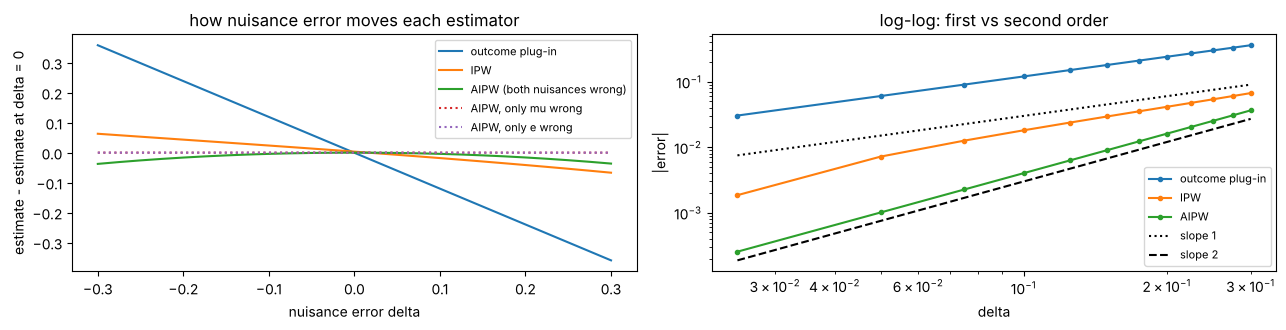

In [2]:
big = make_hospital(400_000, seed=1, n_noise=3, nonlinear=True)
S, age = big.X[:, 0], big.X[:, 1]
mu0 = baseline(S, age, True); mu1 = mu0 + cate(S, age, True); e = np.clip(big.e, 0.02, 0.98)
h0, h1, g = np.sin(3 * S) + age, np.cos(2 * S) - age, 1.5 * S - 1.0      # arbitrary error directions
logit = lambda p: np.log(p / (1 - p)); sig = lambda z: 1 / (1 + np.exp(-z))

def scores(dl, both=True):
    m0, m1 = mu0 + dl * h0, mu1 + dl * h1
    eh = np.clip(sig(logit(e) + dl * g), 0.01, 0.99)
    Tb, Yb = big.T, big.Y
    plug = np.mean(m1 - m0)
    ipw = np.mean(Tb * Yb / eh - (1 - Tb) * Yb / (1 - eh))
    aipw = np.mean(m1 - m0 + Tb * (Yb - m1) / eh - (1 - Tb) * (Yb - m0) / (1 - eh))
    aipw_mu = np.mean(m1 - m0 + Tb * (Yb - m1) / e - (1 - Tb) * (Yb - m0) / (1 - e))       # only mu wrong
    aipw_e = np.mean(mu1 - mu0 + Tb * (Yb - mu1) / eh - (1 - Tb) * (Yb - mu0) / (1 - eh))  # only e wrong
    return plug, ipw, aipw, aipw_mu, aipw_e

deltas = np.linspace(-0.3, 0.3, 25)
R = np.array([scores(dl) for dl in deltas]); ref = scores(0.0)[2]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
for k, lab in enumerate(["outcome plug-in", "IPW", "AIPW (both nuisances wrong)", "AIPW, only mu wrong", "AIPW, only e wrong"]):
    ax[0].plot(deltas, R[:, k] - ref, label=lab, ls="-" if k < 3 else ":")
ax[0].set_xlabel("nuisance error delta"); ax[0].set_ylabel("estimate - estimate at delta = 0"); ax[0].legend(fontsize=8)
ax[0].set_title("how nuisance error moves each estimator")
pos = deltas > 0
for k, lab in enumerate(["outcome plug-in", "IPW", "AIPW"]):
    ax[1].loglog(deltas[pos], np.abs(R[pos, k] - ref) + 1e-6, "o-", ms=3, label=lab)
ax[1].loglog(deltas[pos], 0.3 * deltas[pos], "k:", label="slope 1"); ax[1].loglog(deltas[pos], 0.3 * deltas[pos] ** 2, "k--", label="slope 2")
ax[1].set_xlabel("delta"); ax[1].set_ylabel("|error|"); ax[1].legend(fontsize=8); ax[1].set_title("log-log: first vs second order")
plt.tight_layout(); plt.show()

The plug-in and IPW errors are linear in $\delta$; the AIPW error is quadratic, and it vanishes exactly when *either*
nuisance is right (the dotted lines are flat: **double robustness**). If each nuisance converges at rate $n^{-1/4}$,
which flexible ML models can achieve, the AIPW bias is $O(n^{-1/2})$ and does not spoil a $\sqrt n$ confidence
interval. The plug-in would need $n^{-1/2}$ nuisances, which only correctly specified parametric models achieve.

## 2. Regularization bias with real ML nuisances

Now fit the nuisances with kernel ridge and penalized logistic regression, at increasing regularization (more bias in
the nuisances), and compare the three estimators over 20 datasets.

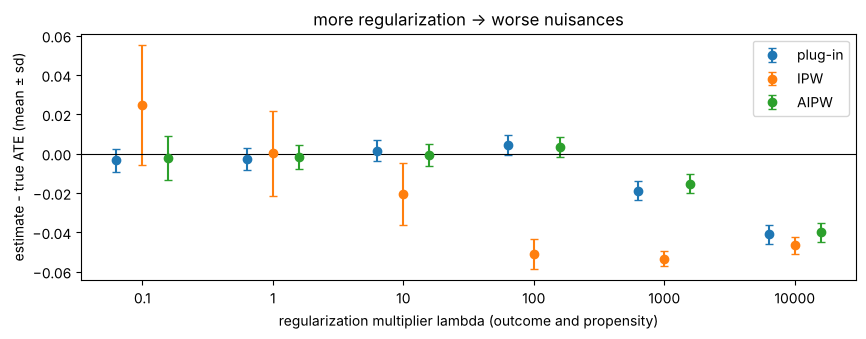

In [3]:
lams = [0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0]
res = {k: [] for k in ["plug-in", "IPW", "AIPW"]}
for lam in lams:
    out = {k: [] for k in res}
    for r in range(20):
        dd = make_hospital(2000, seed=100 + r, n_noise=3, nonlinear=True)
        nu = E.cross_fit_nuisances(dd.X, dd.T, dd.Y,
                                   outcome_model=lambda: KernelRidge(200, 1.5, lam),
                                   propensity_model=lambda: Logistic(lam=1e-3 * lam, n_features=100, lengthscale=1.5))
        out["plug-in"].append(np.mean(nu["mu1"] - nu["mu0"]) - dd.ate)
        out["IPW"].append(E.ipw(dd.X, dd.T, dd.Y, e=nu["e"]).ate - dd.ate)
        out["AIPW"].append(E.aipw(dd.X, dd.T, dd.Y, nuis=nu).ate - dd.ate)
    for k in res:
        res[k].append((np.mean(out[k]), np.std(out[k])))
fig, ax = plt.subplots(figsize=(10, 3.2))
for i, k in enumerate(res):
    m = np.array(res[k]); x = np.arange(len(lams)) + (i - 1) * 0.2
    ax.errorbar(x, m[:, 0], yerr=m[:, 1], fmt="o", capsize=3, label=k)
ax.axhline(0, color="k", lw=0.8); ax.set_xticks(range(len(lams)), [f"{l:g}" for l in lams]); ax.set_xlabel("regularization multiplier lambda (outcome and propensity)")
ax.set_ylabel("estimate - true ATE (mean ± sd)"); ax.legend(); ax.set_title("more regularization -> worse nuisances"); plt.show()

Over-smoothing the propensity model ruins IPW first; over-smoothing the outcome model ruins the plug-in later. AIPW
stays centered as long as *one* of the two is decent, because its error is the *product* of the two nuisance errors.
At the far right both nuisances are badly over-regularized and AIPW fails too: double robustness is not magic, it
needs at least one good model (and, for valid intervals, both converging at rate $n^{-1/4}$).

## 3. Why cross-fitting

Orthogonality removes first-order *bias*. A second problem is **overfitting**: if $\hat\mu$ is fitted on the same unit
it is evaluated on, it partly memorizes that unit's noise, and the residual $Y_i - \hat\mu(X_i)$ is too small.
Cross-fitting predicts each unit with models fitted on the other folds. Here the outcome model is deliberately
flexible (1000 random features, almost no penalty).

In [4]:
def aipw_no_crossfit(dd, om, pm):
    m0 = om().fit(dd.X[dd.T == 0], dd.Y[dd.T == 0]).predict(dd.X)
    m1 = om().fit(dd.X[dd.T == 1], dd.Y[dd.T == 1]).predict(dd.X)
    eh = np.clip(pm().fit(dd.X, dd.T).predict(dd.X), 0.01, 0.99)
    phi = m1 - m0 + dd.T * (dd.Y - m1) / eh - (1 - dd.T) * (dd.Y - m0) / (1 - eh)
    return phi.mean(), phi.std() / np.sqrt(len(phi))
om = lambda: KernelRidge(1000, 0.7, 1e-4); pm = lambda: Logistic(1e-3, 100, 1.5)
cover = {"same data": [], "cross-fitted": []}; err = {"same data": [], "cross-fitted": []}
for r in range(30):
    dd = make_hospital(1000, seed=200 + r, n_noise=3, nonlinear=True)
    a, se = aipw_no_crossfit(dd, om, pm)
    cover["same data"].append(abs(a - dd.ate) < 1.96 * se); err["same data"].append(a - dd.ate)
    est = E.aipw(dd.X, dd.T, dd.Y, outcome_model=om, propensity_model=pm)
    cover["cross-fitted"].append(abs(est.ate - dd.ate) < 1.96 * est.se); err["cross-fitted"].append(est.ate - dd.ate)
for k in cover:
    print(f"{k:>13}: mean error {np.mean(err[k]):+.4f}, RMSE {np.sqrt(np.mean(np.square(err[k]))):.4f}, 95% CI coverage {np.mean(cover[k]):.0%}")

    same data: mean error +0.0022, RMSE 0.0296, 95% CI coverage 57%
 cross-fitted: mean error -0.0031, RMSE 0.0305, 95% CI coverage 97%


## 4. Coverage of the DML confidence interval

With orthogonality and cross-fitting, $\hat\psi = \frac1n\sum_i \phi_i$ is asymptotically normal with variance
$\text{Var}(\phi)/n$, so $\hat\psi \pm 1.96\,\text{sd}(\phi)/\sqrt n$ is a valid 95% interval, *as if the nuisances had
been known*.

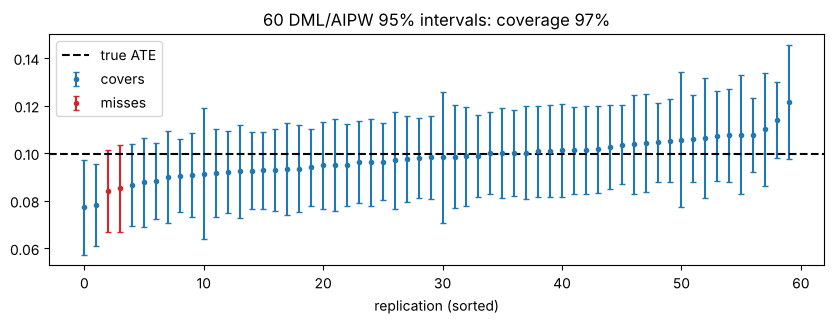

In [5]:
ests = []
for r in range(60):
    dd = make_hospital(2000, seed=300 + r, n_noise=3, nonlinear=True)
    est = E.aipw(dd.X, dd.T, dd.Y)
    ests.append((est.ate, est.se, dd.ate))
ests = np.array(ests)
fig, ax = plt.subplots(figsize=(10, 3))
o = np.argsort(ests[:, 0])
hit = np.abs(ests[o, 0] - ests[o, 2]) < 1.96 * ests[o, 1]
ax.errorbar(np.arange(60)[hit], ests[o, 0][hit], yerr=1.96 * ests[o, 1][hit], fmt="o", ms=3, capsize=2, label="covers")
ax.errorbar(np.arange(60)[~hit], ests[o, 0][~hit], yerr=1.96 * ests[o, 1][~hit], fmt="o", ms=3, capsize=2, color="tab:red", label="misses")
ax.axhline(ests[:, 2].mean(), color="k", ls="--", label="true ATE"); ax.set_xlabel("replication (sorted)"); ax.legend()
ax.set_title(f"60 DML/AIPW 95% intervals: coverage {hit.mean():.0%}"); plt.show()

## 5. The partially linear model targets a different estimand

The original DML paper's headline example is the partially linear model $Y = \theta T + g(X) + \varepsilon$: residualize
$Y$ and $T$ on $X$ with ML, then regress residual on residual (FWL with ML first stages). Under a homogeneous effect,
$\theta$ is the ATE. Under heterogeneity, it is the **overlap-weighted** effect
$\theta = E[e(X)(1-e(X))\tau(X)] / E[e(X)(1-e(X))]$, the same variance weighting as OLS in the regression lecture.

In [6]:
w_ = big.e * (1 - big.e)
target_plr = np.sum(w_ * big.tau) / np.sum(w_)
plr, aipw_ = [], []
for r in range(20):
    dd = make_hospital(2000, seed=400 + r, n_noise=3, nonlinear=True)
    nu = E.cross_fit_nuisances(dd.X, dd.T, dd.Y)
    plr.append(E.dml_plr(dd.X, dd.T, dd.Y, nuis=nu).ate); aipw_.append(E.aipw(dd.X, dd.T, dd.Y, nuis=nu).ate)
print(f"ATE                             {big.ate:+.3f}   <- AIPW   mean over 20 datasets {np.mean(aipw_):+.3f}")
print(f"overlap-weighted effect         {target_plr:+.3f}   <- DML-PLR mean over 20 datasets {np.mean(plr):+.3f}")

ATE                             +0.100   <- AIPW   mean over 20 datasets +0.102
overlap-weighted effect         +0.123   <- DML-PLR mean over 20 datasets +0.124


Neither is wrong; they answer different questions. The overlap-weighted effect emphasizes patients for whom
treatment was most uncertain (severity near 1), which has lower variance but is not "the effect of operating on
everybody".

## 6. Orthogonal CATE learning: the R-learner

Foster & Syrgkanis ask: what if the target is a whole function $\tau(x)$, fitted by an ML model, while nuisances are
estimated in a first stage? Their answer is to minimize an **orthogonal loss**. For the CATE it is the
Robinson / R-learner loss

$$\hat\tau = \arg\min_\tau \frac1n\sum_i \Big( (Y_i - \hat m(X_i)) - \tau(X_i)\,(T_i - \hat e(X_i)) \Big)^2, \qquad m(x) = E[Y|X=x],$$

whose excess risk is only second-order sensitive to errors in $\hat m, \hat e$. It is a weighted regression of
$(Y - \hat m)/(T - \hat e)$ on $X$ with weights $(T - \hat e)^2$. Compared with the T-learner (fit
$\hat\mu_1 - \hat\mu_0$, a plug-in), the R-learner should win when the outcome surfaces are much more complicated than
the effect itself, which is exactly the hospital: the baseline is wiggly, $\tau(x)$ is nearly linear.

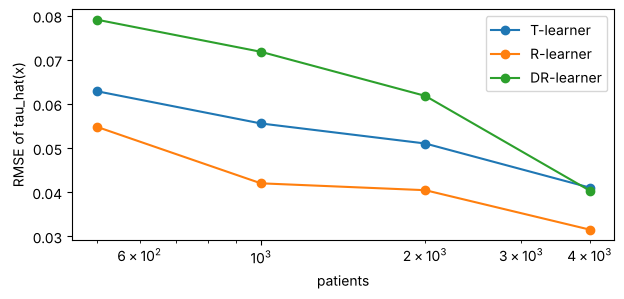

In [7]:
ns = [500, 1000, 2000, 4000]
pehe = {"T-learner": [], "R-learner": [], "DR-learner": []}
for n in ns:
    out = {k: [] for k in pehe}
    for r in range(6):
        dd = make_hospital(n, seed=500 + r, n_noise=3, nonlinear=True)
        nu = E.cross_fit_nuisances(dd.X, dd.T, dd.Y)
        for k, f in [("T-learner", lambda: E.t_learner(dd.X, dd.T, dd.Y)),
                     ("R-learner", lambda: E.r_learner(dd.X, dd.T, dd.Y, nuis=nu)),
                     ("DR-learner", lambda: E.dr_learner(dd.X, dd.T, dd.Y, nuis=nu))]:
            out[k].append(np.sqrt(np.mean((f().cate(big.X[:20000]) - big.tau[:20000]) ** 2)))
    for k in pehe:
        pehe[k].append(np.mean(out[k]))
fig, ax = plt.subplots(figsize=(7, 3))
for k in pehe:
    ax.plot(ns, pehe[k], "o-", label=k)
ax.set_xscale("log"); ax.set_xlabel("patients"); ax.set_ylabel("RMSE of tau_hat(x)"); ax.legend(); plt.show()

## What carries over

* The doubly robust score is the same object as the IPW/DR estimator of [03](../../../03-propensity-scores/); what is
  new here is *why* it tolerates ML nuisances (orthogonality) and the recipe that makes the CI valid (cross-fitting).
* TMLE and Dragonnet ([07](../../../07-causal-deep-learning/)) reach the same orthogonality by a targeting step instead
  of an additive correction.
* The same correction term (the residual divided by the propensity) is the doubly robust policy value of contextual
  bandits and off-policy RL ([11](../../../11-reinforcement-learning/)).
* [12](../../../12-one-dataset-many-estimators/) compares these estimators with every other method of the course on the
  same data.